# Synthetic repeated-facies SC-PaCMAP results

The data generator is copied verbatim from the original
`03_synthetic_sc_pacmap_benchmark.ipynb` into `synthetic_benchmark.py`.
The same metadata, feature order, float64 raw arrays, and separate standardization
are retained. Data seed 42 gives the original 1,024-sample, 50-feature dataset.

Thirty algorithm seeds (0 through 29) fit this fixed dataset for the three-metric
range plots and the trade-off cloud. The seed-42 embedding board shows K-means
clusters at K=4. Lambda-cap sensitivity uses ten algorithm seeds (0 through 9).
Labels enter evaluation and reference-K selection only. No result files are written.


In [21]:
from __future__ import annotations
import os, sys
from pathlib import Path

# Keep an already imported kernel's Numba pool size; use one active thread.
# On a fresh kernel, configure the pool before numerical imports.
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import matplotlib.pyplot as plt
import numba, numpy as np, pandas as pd, seaborn as sns
numba.set_num_threads(1)
import pacmap, umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
sns.set_theme(style='whitegrid',context='notebook'); plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
def find_root(start=Path.cwd()):
    for candidate in (start.resolve(),*start.resolve().parents):
        if (candidate/'code'/'sc_pacmap'/'sc_pacmap.py').is_file(): return candidate
        nested=candidate/'sc-pacmap-reproducibility'
        if (nested/'code'/'sc_pacmap'/'sc_pacmap.py').is_file(): return nested
    raise FileNotFoundError('Repository root not found')
ROOT=find_root()
for folder in (ROOT/'code'/'sc_pacmap',ROOT/'code'/'spasne'):
    sys.path.insert(0,str(folder)) if str(folder) not in sys.path else None
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_legacy_sc_pacmap, run_sc_pacmap
from spasne_adapter import python_spasne
from notebook_support import localmap_seed
SEEDS = tuple(range(30))
SENSITIVITY_SEEDS = tuple(range(10))
N_NEIGHBORS, K_REFERENCE = 8, 4
DATA_SEED = 42
from synthetic_benchmark import make_synthetic_repeated_facies, FEATURE_COLUMNS, XY_COLUMNS

# Use the original benchmark's generator, metadata, precision, and preprocessing.
data, latent = make_synthetic_repeated_facies(random_state=DATA_SEED)
FEATURES = FEATURE_COLUMNS
features_raw = data[FEATURE_COLUMNS].to_numpy(dtype=np.float64)
coords = data[XY_COLUMNS].to_numpy(dtype=np.float64)
truth = data['facies_id'].to_numpy(dtype=np.int64)
theta = latent['nuisance_theta']
features = StandardScaler().fit_transform(features_raw).astype(np.float32)
xyz = StandardScaler().fit_transform(coords)
features_xy = np.column_stack([features, xyz])
tss = float(np.sum((features - features.mean(0, keepdims=True))**2))
spatial_neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1, n_jobs=1).fit(
    coords).kneighbors(coords, return_distance=False)[:, 1:]
N = len(data)
assert data.shape == (1024, 56)
assert data['patch_id'].nunique() == 16 and data['facies_id'].nunique() == 4
settings_base=dict(n_components=2,n_neighbors=N_NEIGHBORS,mn_ratio=.5,fp_ratio=2.,learning_rate=1.,num_iters=(100,100,250),knn_backend='faiss',verbose=False)
METHODS=['UMAP + XY','PaCMAP + XY','LocalMAP + XY','PaCMAP feature-only','SC-PaCMAP replacement','SC-PaCMAP full graph','SpaSNE']
print(f'{N} samples | 50 features | 16 patches | 4 facies | K={K_REFERENCE}')
K_VALUES = range(2, 11)
COLORS = dict(zip(METHODS, ['#D55E00', '#56B4E9', '#009E73', '#7A5195', '#E15759', '#E60049', '#D4A900']))
MARKERS = dict(zip(METHODS, ['o', '^', 'v', 'P', 'h', '*', 'X']))

1024 samples | 50 features | 16 patches | 4 facies | K=4


## Data walk-through

The facies map, one answer-bearing feature, and the shuffled nuisance angle make the designed mechanism visible before fitting.

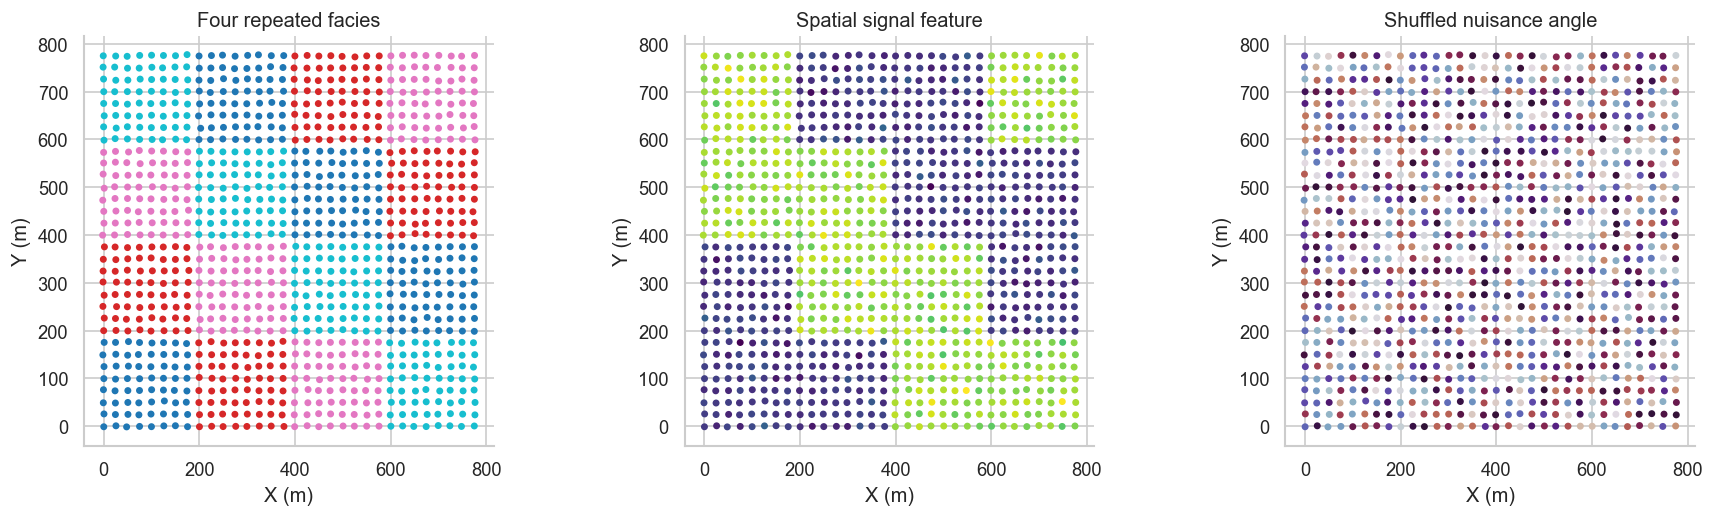

In [22]:
from IPython.display import display
fig,axes=plt.subplots(1,3,figsize=(15,4.2),constrained_layout=True)
axes[0].scatter(coords[:,0],coords[:,1],c=truth,cmap='tab10',s=10); axes[0].set_title('Four repeated facies')
axes[1].scatter(coords[:,0],coords[:,1],c=features[:,0],cmap='viridis',s=10); axes[1].set_title('Spatial signal feature')
axes[2].scatter(coords[:,0],coords[:,1],c=theta,cmap='twilight',s=10); axes[2].set_title('Shuffled nuisance angle')
for ax in axes: ax.set(xlabel='X (m)',ylabel='Y (m)',aspect='equal')
plt.show()

## One seed: embeddings and K=4 evaluation

Each panel colors the raw 2-D embedding by the evaluation-only true label. K-means
still evaluates the same embedding at $K=4$ for the result table below. Cluster IDs
do not correspond between methods, and ground-truth labels are used only for plotting
and the ARI in the result table.

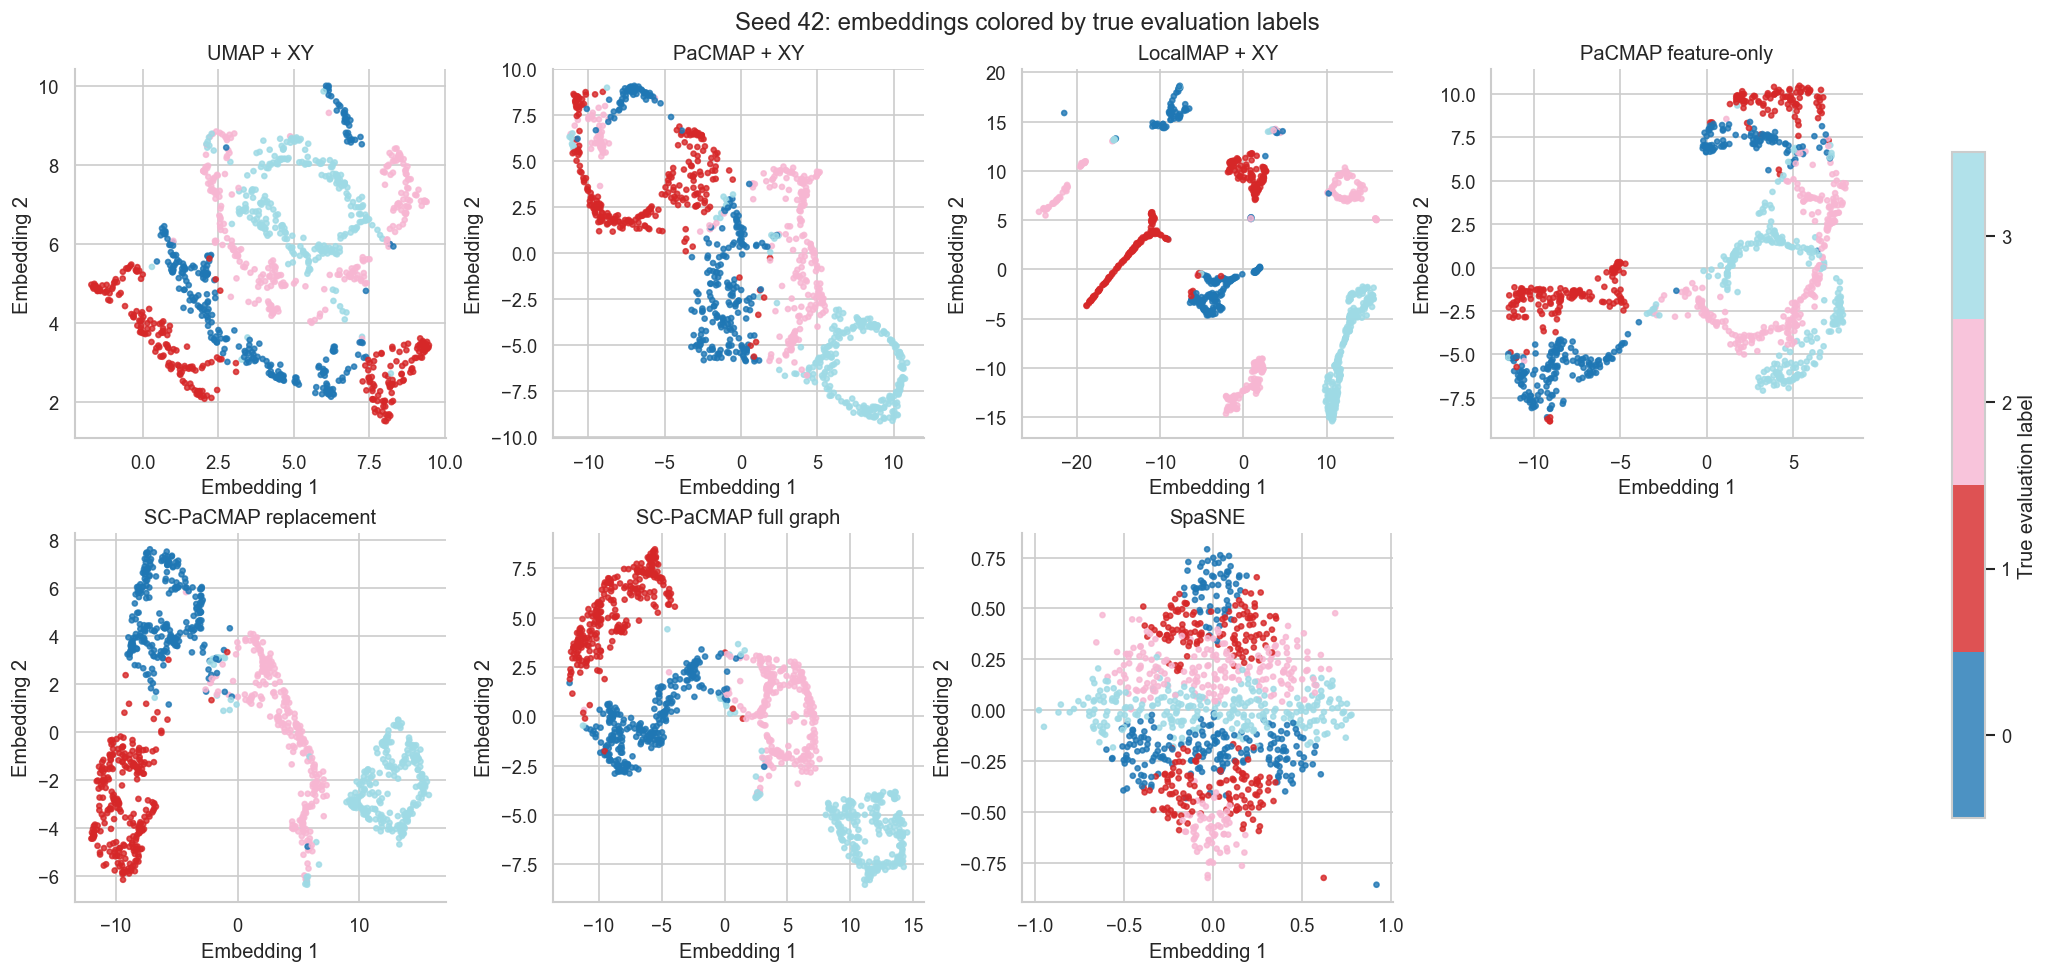

,method,K,H_per_sample,WCSS_TSS,ARI
0,UMAP + XY,4,0.8158,0.9108,0.2699
1,PaCMAP + XY,4,0.8044,0.9112,0.3454
2,LocalMAP + XY,4,0.7439,0.9070,0.4044
3,PaCMAP feature-only,4,0.7803,0.9075,0.2895
4,SC-PaCMAP replacement,4,0.3477,0.8569,0.8855
5,SC-PaCMAP full graph,4,0.3600,0.8580,0.8728
6,SpaSNE,4,0.1249,0.9750,0.1419


Automatic spatial-strength lambda: 0.125


In [23]:
def fit_embeddings(seed, feature_values=features, coordinate_values=coords):
    numba.set_num_threads(1)
    features_with_coordinates = np.column_stack([feature_values, StandardScaler().fit_transform(coordinate_values)])
    settings=PaCMAPSettings(random_state=seed,**settings_base); args={'n_components':2,'n_neighbors':N_NEIGHBORS,'MN_ratio':.5,'FP_ratio':2.,'distance':'euclidean','lr':1.,'num_iters':(100,100,250),'apply_pca':True,'random_state':seed,'save_tree':False,'knn_backend':'faiss'}; out={}
    out['UMAP + XY']=umap.UMAP(n_neighbors=N_NEIGHBORS,n_components=2,metric='euclidean',learning_rate=1.,random_state=seed,n_jobs=1).fit_transform(features_with_coordinates)
    out['PaCMAP + XY']=pacmap.PaCMAP(**args).fit_transform(features_with_coordinates,init='pca',save_pairs=False)
    with localmap_seed(seed):
        out['LocalMAP + XY']=pacmap.LocalMAP(**{**args,'low_dist_thres':10}).fit_transform(np.ascontiguousarray(features_with_coordinates, dtype=np.float64),init='pca',save_pairs=False)
    out['PaCMAP feature-only']=pacmap.PaCMAP(**args).fit_transform(feature_values,init='pca',save_pairs=False)
    r,_=run_legacy_sc_pacmap(feature_values,coordinate_values,settings); out['SC-PaCMAP replacement']=r.embedding
    r,d=run_sc_pacmap(feature_values,coordinate_values,settings); out['SC-PaCMAP full graph']=r.embedding
    out['SpaSNE']=python_spasne(feature_values,coordinate_values,random_state=seed,alpha=10.,beta=5.,exaggeration=4,perplexity=50,theta=.5,max_iter=1000,use_pca=True,spasne_dir=ROOT/'code'/'spasne'/'spasne_original')
    return out,d


def entropy(labels, neighbors=spatial_neighbors):
    total = 0.
    for n in neighbors:
        counts = np.bincount(labels[n])
        p = counts[counts > 0] / neighbors.shape[1]
        total -= float(np.sum(p * np.log(p)))
    return total / len(labels)


def wcss(labels, k=K_REFERENCE, feature_values=features, total_ss=tss):
    centers = np.vstack([feature_values[labels == j].mean(0) for j in range(k)])
    return float(np.sum((feature_values - centers[labels])**2)) / total_ss


def evaluate(labels, k, feature_values=features, neighbors=spatial_neighbors,
             label_truth=truth, total_ss=tss):
    return {'H_per_sample': entropy(labels, neighbors),
            'WCSS_TSS': wcss(labels, k, feature_values, total_ss),
            'ARI': adjusted_rand_score(label_truth, labels)}

one_seed_embeddings, one_seed_diag = fit_embeddings(42)
# Convert stored embeddings to float64 before K-means evaluation.
one_seed_embeddings = {m: np.asarray(y, dtype=np.float64) for m, y in one_seed_embeddings.items()}
one_seed_rows = []
fig, axes = plt.subplots(2, 4, figsize=(17, 8), constrained_layout=True)
true_label_cmap = plt.get_cmap('tab20', len(np.unique(truth)))
for ax, method in zip(axes.flat, METHODS):
    embedding = one_seed_embeddings[method]
    cluster_labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                    random_state=1000 + K_REFERENCE).fit_predict(embedding)
    one_seed_rows.append({'method': method, 'K': K_REFERENCE, **evaluate(cluster_labels, K_REFERENCE)})
    points = ax.scatter(embedding[:, 0], embedding[:, 1], c=truth,
                        cmap=true_label_cmap, vmin=truth.min() - .5, vmax=truth.max() + .5, s=9, alpha=.8)
    ax.set(title=method, xlabel='Embedding 1', ylabel='Embedding 2')
axes.flat[-1].set_visible(False)
fig.colorbar(points, ax=list(axes.flat[:-1]), ticks=sorted(np.unique(truth)),
             label='True evaluation label', shrink=.8)
fig.suptitle('Seed 42: embeddings colored by true evaluation labels')
plt.show()
one_seed_results = pd.DataFrame(one_seed_rows)
display(one_seed_results.round(4))
print(f'Automatic spatial-strength lambda: {one_seed_diag.spatial_strength_lambda:.3f}')

## Thirty-seed evaluation curves with stability ranges

The three panels use the old notebooks' raw metrics: mean windowed entropy $H/N$
and feature-space WCSS/TSS (lower is better), and adjusted Rand index (higher is better).
K-means uses the raw embedding with 20 initializations. The vertical line marks the
reference K. Shading shows observed min-max ranges, not confidence intervals.

All 30 algorithm seeds run on the same full synthetic dataset generated with data seed 42. Lines show across-seed
medians and bands show the seed range at each K.

Completed algorithm seed 0


Completed algorithm seed 1


Completed algorithm seed 2


Completed algorithm seed 3


Completed algorithm seed 4


...

Completed algorithm seed 25


Completed algorithm seed 26


Completed algorithm seed 27


Completed algorithm seed 28


Completed algorithm seed 29


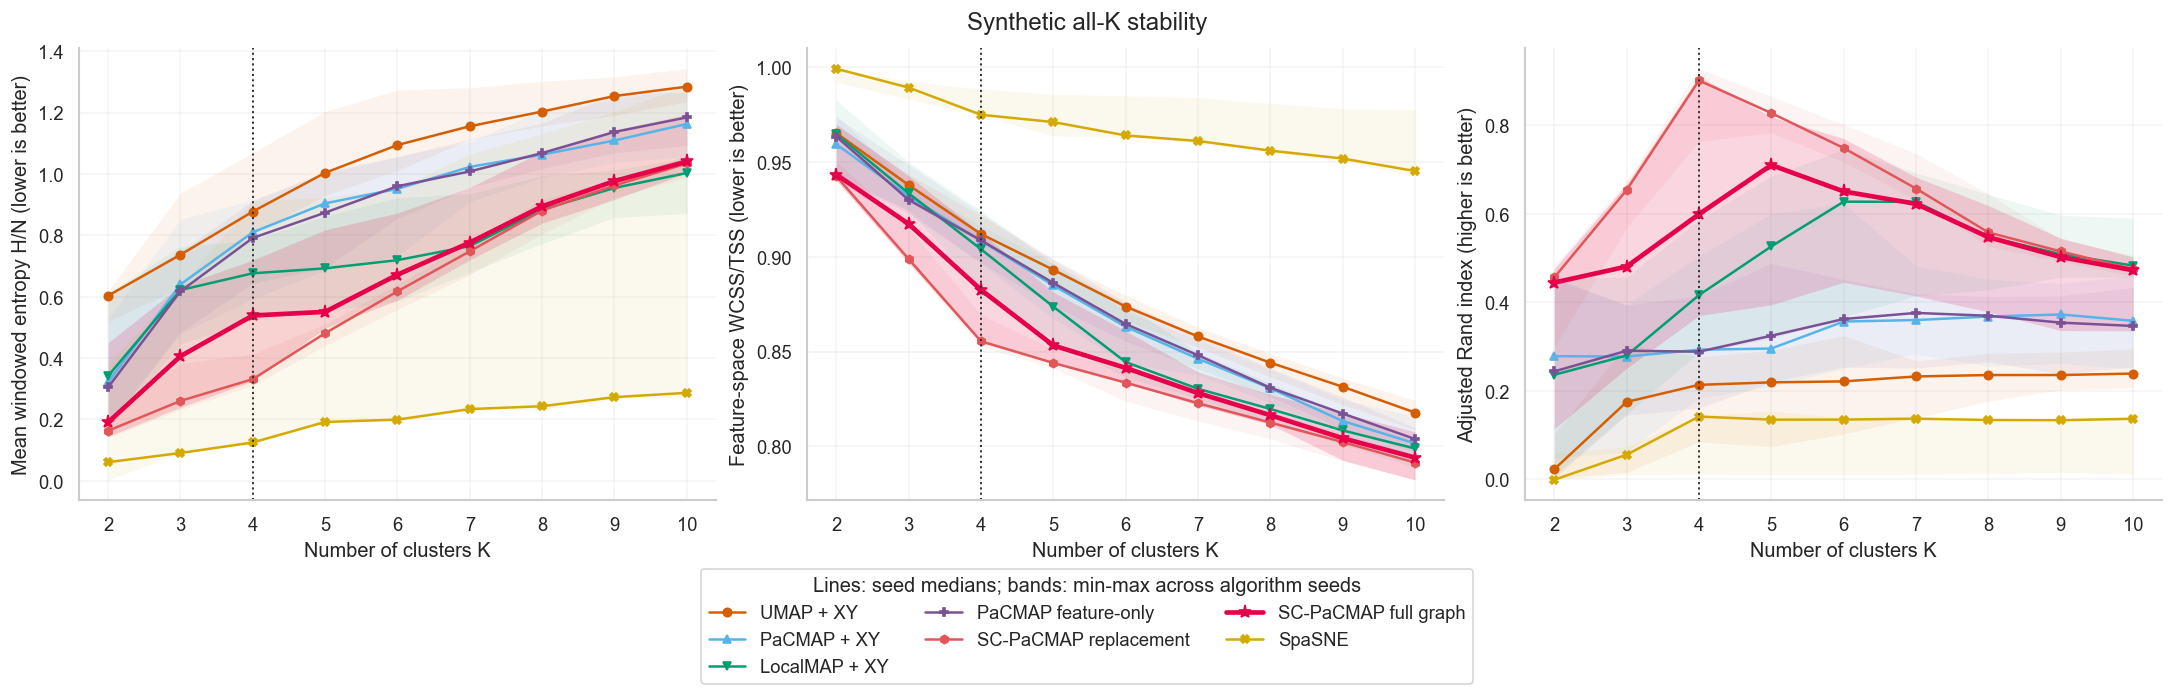

In [24]:
rows = []
for seed in SEEDS:
    embeddings = one_seed_embeddings if seed == 42 else fit_embeddings(seed)[0]
    for method in METHODS:
        for k in K_VALUES:
            labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                            random_state=1000 + k).fit_predict(embeddings[method])
            rows.append({'seed': seed, 'method': method, 'K': k, **evaluate(labels, k)})
    print(f'Completed algorithm seed {seed}', flush=True)
results = pd.DataFrame(rows)
range_results = results

metric_specs = [('H_per_sample', 'Mean windowed entropy H/N', 'lower is better'),
                ('WCSS_TSS', 'Feature-space WCSS/TSS', 'lower is better'),
                ('ARI', 'Adjusted Rand index', 'higher is better')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.7), constrained_layout=True)
for ax, (metric, ylabel, direction) in zip(axes, metric_specs):
    for method in METHODS:
        summary = range_results[range_results.method == method].groupby('K')[metric].agg(['median', 'min', 'max'])
        primary = method == 'SC-PaCMAP full graph'
        ax.fill_between(summary.index, summary['min'], summary['max'], color=COLORS[method],
                        alpha=.16 if primary else .07, linewidth=0)
        ax.plot(summary.index, summary['median'], color=COLORS[method], marker=MARKERS[method],
                linewidth=2.8 if primary else 1.5, markersize=8 if primary else 5, label=method)
    ax.axvline(K_REFERENCE, color='#333333', ls=':', lw=1.2)
    ax.set(xlabel='Number of clusters K', ylabel=f'{ylabel} ({direction})', xticks=list(K_VALUES))
    ax.grid(alpha=.2)
fig.suptitle('Synthetic all-K stability')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3,
           title='Lines: seed medians; bands: min-max across algorithm seeds')
plt.show()

## Trade-off cloud at $K=4$

Each faint point is one algorithm-seed run.
The large outlined marker is the across-seed median.
The axes retain the old raw entropy and WCSS/TSS scales: lower-left is better jointly.

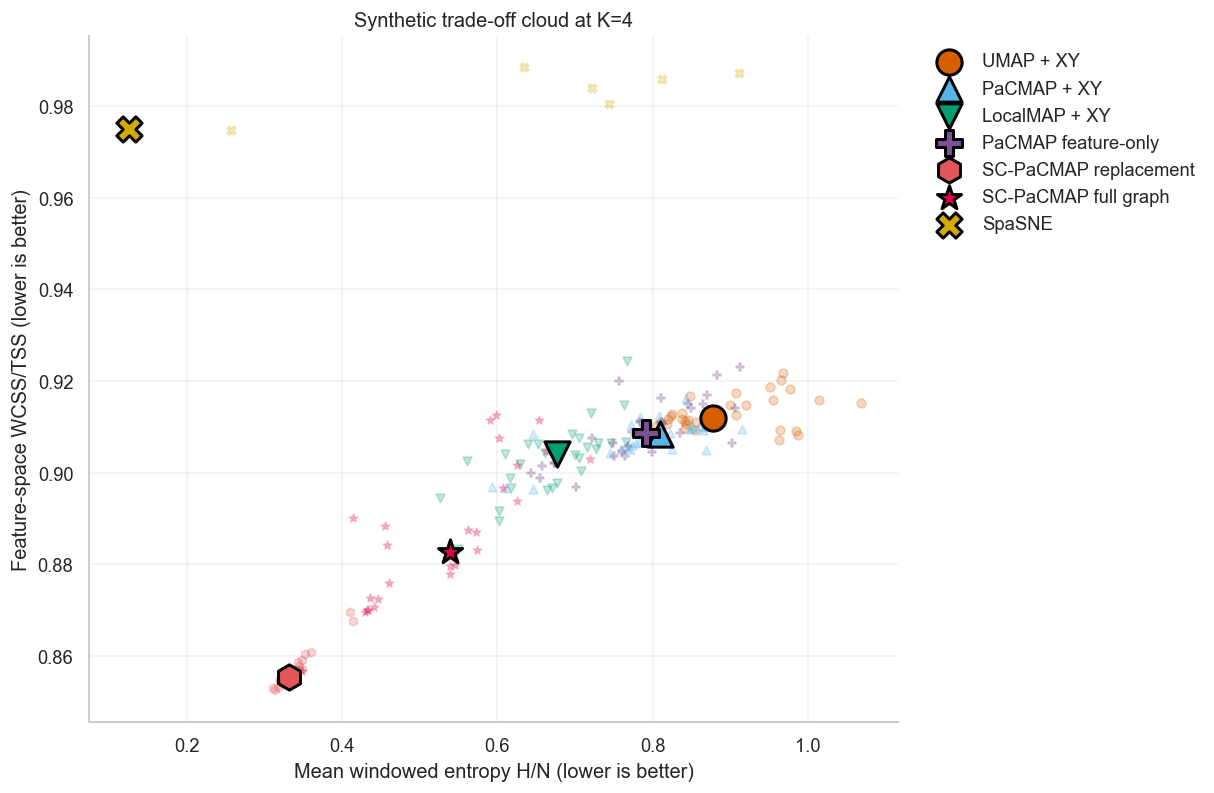

In [25]:
cloud = results[results.K == K_REFERENCE]
cloud_medians = range_results[range_results.K == K_REFERENCE].groupby('method')[['H_per_sample', 'WCSS_TSS']].median()
fig, ax = plt.subplots(figsize=(10, 6.5), constrained_layout=True)
for method in METHODS:
    part = cloud[cloud.method == method]
    ax.scatter(part.H_per_sample, part.WCSS_TSS, color=COLORS[method],
               marker=MARKERS[method], s=28, alpha=.24)
    median = cloud_medians.loc[method]
    ax.scatter(median.H_per_sample, median.WCSS_TSS, color=COLORS[method], marker=MARKERS[method],
               s=230, edgecolor='black', linewidth=1.8, label=method, zorder=4)
ax.set(xlabel='Mean windowed entropy H/N (lower is better)',
       ylabel='Feature-space WCSS/TSS (lower is better)', title=f'Synthetic trade-off cloud at K={K_REFERENCE}')
ax.grid(alpha=.25)
ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

## Lambda-cap sensitivity at $K=4$

Ten algorithm seeds sweep `SCPaCMAPConfig(max_target_share=...)` on the fixed
seed-42 synthetic dataset. This parameter caps both the automatically inferred lambda used
in the share calculation and the final Phase-3 spatial-attraction share; it does
not replace lambda with a manually fixed value. The default benchmark remains at 0.95.
The dashed line marks the data-derived automatic lambda for reference.

Lines show seed medians; shading shows min-max seed ranges. Here the two evaluation
scores are percentages (higher is better): spatial contiguity is
$100(1-(H/N)/\log K)$ and multivariate delineation is $100(1-\mathrm{WCSS}/\mathrm{TSS})$.

Completed sensitivity seed 0
Completed sensitivity seed 1
Completed sensitivity seed 2
Completed sensitivity seed 3
Completed sensitivity seed 4
Completed sensitivity seed 5
Completed sensitivity seed 6
Completed sensitivity seed 7
Completed sensitivity seed 8
Completed sensitivity seed 9


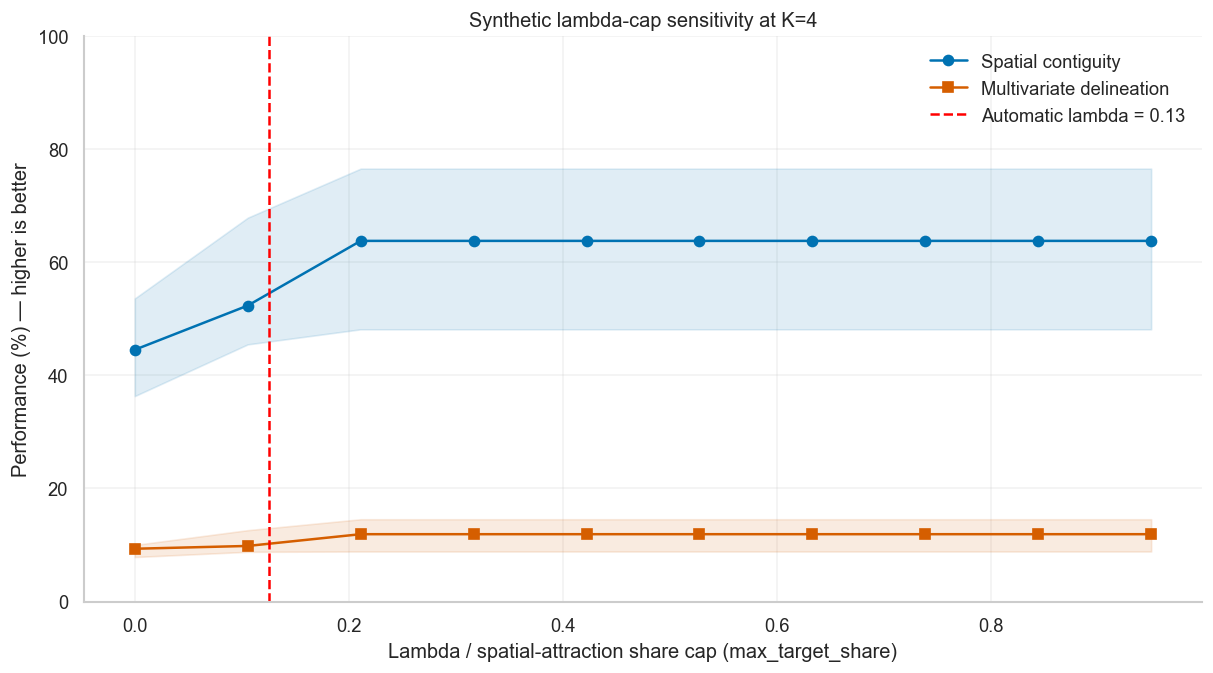

In [26]:
lambda_caps = np.linspace(0., .95, 10)
lambda_rows = []
for seed in SENSITIVITY_SEEDS:
    settings = PaCMAPSettings(random_state=seed, **settings_base)
    for cap in lambda_caps:
        result, diag = run_sc_pacmap(features, coords, settings,
                                    config=SCPaCMAPConfig(max_target_share=float(cap)))
        labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                        random_state=1000 + K_REFERENCE).fit_predict(result.embedding)
        metrics = evaluate(labels, K_REFERENCE)
        lambda_rows.append({'seed': seed, 'lambda_cap': cap,
                            'automatic_lambda': diag.spatial_strength_lambda,
                            'target_share': diag.automatic_target_share,
                            'spatial': 100 * (1 - metrics['H_per_sample'] / np.log(K_REFERENCE)),
                            'multivariate': 100 * (1 - metrics['WCSS_TSS'])})
    print(f'Completed sensitivity seed {seed}', flush=True)
lambda_results = pd.DataFrame(lambda_rows)
automatic_lambda = float(lambda_results.automatic_lambda.median())
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
for metric, label, color, marker in [
    ('spatial', 'Spatial contiguity', '#0072B2', 'o'),
    ('multivariate', 'Multivariate delineation', '#D55E00', 's'),
]:
    summary = lambda_results.groupby('lambda_cap')[metric].agg(['median', 'min', 'max'])
    ax.fill_between(summary.index, summary['min'], summary['max'], color=color, alpha=.12)
    ax.plot(summary.index, summary['median'], color=color, marker=marker, label=label)
ax.axvline(automatic_lambda, color='red', ls='--', label=f'Automatic lambda = {automatic_lambda:.2f}')
ax.set(xlabel='Lambda / spatial-attraction share cap (max_target_share)',
       ylabel='Performance (%) — higher is better', ylim=(0, 100),
       title=f'Synthetic lambda-cap sensitivity at K={K_REFERENCE}')
ax.legend(frameon=False)
ax.grid(alpha=.25)
plt.show()